<a href="https://colab.research.google.com/github/Marina202005/ML-Seminar_HorhoceaMarina/blob/main/HORHOCEA_MARINA_LP3_tema.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [3]:
# TODO 1.1 — procentul de valori lipsă pe coloană
missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
print("Procentul de valori lipsă:\n", missing_percent)

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
cols_to_drop = missing_percent[missing_percent > 50].index
df = df.drop(columns=cols_to_drop)
print("\nColoana care dispare (are > 50% valori lipsă):", list(cols_to_drop))

Procentul de valori lipsă:
 deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64

Coloana care dispare (are > 50% valori lipsă): ['deck']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [6]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
# TODO 2.2 — verificare + comparație deviație standard
print("Valori lipsă rămase:\n", df.isnull().sum())
print("\nDeviația standard înainte de imputare:", age_inainte.std())
print("Deviația standard după imputare:", df['age'].std())

Valori lipsă rămase:
 survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64

Deviația standard înainte de imputare: 13.019696550973194
Deviația standard după imputare: 13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.787316519674893
Skewness log_fare: 0.3949280095189306
Transformarea a redus semnificativ asimetria (skewness-ul s-a apropiat de 0).


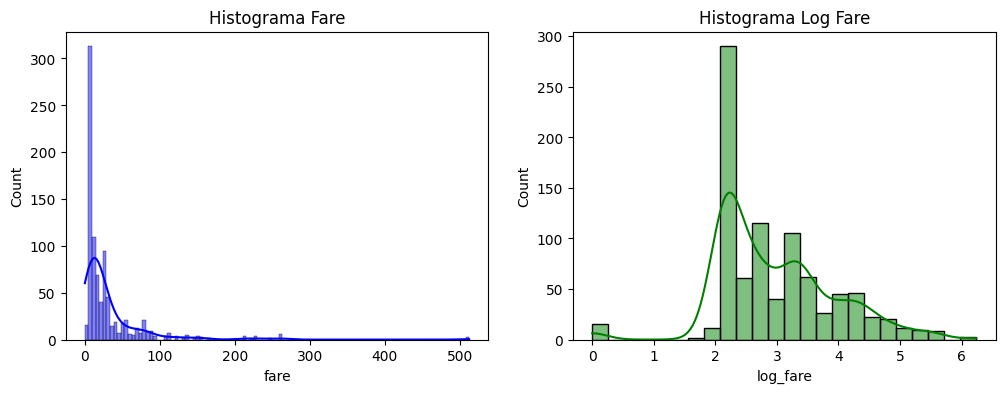

In [9]:
# TODO 3.1 — skewness fare

print("Skewness fare:", df['fare'].skew())
# TODO 3.2 — coloana log_fare + skewness

df['log_fare'] = np.log1p(df['fare'])
print("Skewness log_fare:", df['log_fare'].skew())
print("Transformarea a redus semnificativ asimetria (skewness-ul s-a apropiat de 0).")
# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['fare'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Histograma Fare')
sns.histplot(df['log_fare'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Histograma Log Fare')
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [16]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['fare'] < lower_bound) | (df['fare'] > upper_bound)]
print(f"Număr de outlieri pentru fare: {len(outliers)}")
# TODO 4.2 — fare_capped (clip) + maxim înainte/după
print("Maxim înainte:", df['fare'].max())
df['fare_capped'] = df['fare'].clip(lower=lower_bound, upper=upper_bound)
print("Maxim după (fare_capped):", df['fare_capped'].max())

Număr de outlieri pentru fare: 116
Maxim înainte: 512.3292
Maxim după (fare_capped): 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [18]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
cols_to_encode = [col for col in ['sex', 'embarked'] if col in df.columns]
if cols_to_encode:
    df = pd.get_dummies(df, columns=cols_to_encode, drop_first=True, dtype=int)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()
df[['age', 'fare_capped']] = scaler.fit_transform(df[['age', 'fare_capped']])

print("Verificare medie și std:")
print(f"age - Medie: {df['age'].mean():.4f}, Std: {df['age'].std():.4f}")
print(f"fare_capped - Medie: {df['fare_capped'].mean():.4f}, Std: {df['fare_capped'].std():.4f}")

Verificare medie și std:
age - Medie: 0.0000, Std: 1.0006
fare_capped - Medie: 0.0000, Std: 1.0006


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*


#Am imputat age deoarece avea un procent redus de valori lipsă și o importanță mare pentru analiză, în timp ce deck a fost eliminat deoarece avea peste 50% valori lipsă

```

